# 10f Stand-alone Automated Concept Refinement Cycle

This combines the inspectable stages in 10a–10d: prepare the pair-year corpus and split, create a mutable working catalog from the seed reference or resume the current working catalog, classify with the same Jev cache, build yearly signals, and run development forecasts. It repeats the proposal/classify/evaluate stages as a development-only refinement loop. This notebook can run from a clean checkout without first running 10a or 10b.

Edit the parameter block in the setup cell for pathogen limit, split, models, classification, forecasts, and refinement size. Defaults use the configured Jev model and `CHILD_GENERATION_MODEL` (default `gpt-6-astra`). The default search uses three rounds, up to three Pareto-front parents per round, and three children per parent. After refinement it reports exploratory concept attributions for the three highest-SI development pairs.

Jev labels are cached per abstract and concept definition, so rerunning or adding children reuses unchanged labels. Proposals, round summaries, forecasts, catalog snapshots, and Pareto tables are saved under `outputs/concept_search/automated_refinement/`. Confirmation remains separate in notebook 10e after the catalog is frozen.


In [1]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines import automated_concept_refinement as automated_refinement_module
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

# Corpus and split parameters. All antibiotics are retained for selected pathogens.
NUM_PATHOGENS = 2
HELDOUT_FRACTION = 0.20
SPLIT_SEED = 42
RESET_CATALOG_TO_SEEDS = True
YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
ABSTRACT_CACHE_PATH = cfg_path(PIPELINE_CONFIG, "paths.abstract_cache", PROJECT_ROOT)
SI_PATH = PROJECT_ROOT / "outputs" / "parquets" / "yearly_si.parquet"
PATHOGEN_PRIORITY_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_priority", PROJECT_ROOT)
MIN_PATHOGENIC_INDEX = float(cfg(PIPELINE_CONFIG, "collection.min_pathogenic_index", 0))

# Jev classification and LLM proposal parameters.
JEV_MODEL = str(cfg(PIPELINE_CONFIG, "system1.model", "typesafe/jev-1.13"))
MAX_WORKERS = int(cfg(PIPELINE_CONFIG, "system1.max_workers", 128))
FORECAST_MAX_WORKERS = 4  # Independent model/horizon fits; set -1 to use all available CPUs.
MAX_CLASSIFICATION_CALLS = None
CHILD_GENERATION_MODEL = str(cfg(PIPELINE_CONFIG, "llm.child_generation_model", "gpt-6-astra"))
LLM_TEMPERATURE = 0
LLM_MAX_TOKENS = 4000
MAX_EXAMPLES_PER_PARENT = 30
PROPOSAL_EXAMPLE_SEED = 42
POSITIVE_EXAMPLE_THRESHOLD = 0.5
SEMANTIC_DUPLICATE_THRESHOLD = 0.85  # Jev confidence cutoff for skipping an equivalent child.

# Expanding-window forecast parameters.
FIT_START_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_start_year", 2000))
FORECAST_ORIGIN_END_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_end_year", 2023))
LAG_LENGTH = 3
FORECAST_HORIZONS = (1, 2, 3)
MIN_PRIOR_OBSERVATIONS = 10
FORECAST_PROGRESS_EVERY = 200
FRONTIER_DISPLAY_ROWS = 30

# Automated search parameters.
N_ITER = 1
K_PARENTS = 3
NUM_CHILDREN = 3
ATTRIBUTION_NUM_PAIRS = 3  # Highest-SI development pairs to report in the final exploratory attribution.
RUN_AUTOMATED_CYCLE = True

PARAMETERS = {name: value for name, value in locals().copy().items() if name in {
    'YEARLY_SCREENED_PATH', 'ABSTRACT_CACHE_PATH', 'SI_PATH', 'PATHOGEN_PRIORITY_PATH', 'MIN_PATHOGENIC_INDEX', 'NUM_PATHOGENS', 'HELDOUT_FRACTION', 'SPLIT_SEED', 'RESET_CATALOG_TO_SEEDS', 'JEV_MODEL', 'MAX_WORKERS', 'FORECAST_MAX_WORKERS', 'MAX_CLASSIFICATION_CALLS', 'CHILD_GENERATION_MODEL', 'LLM_TEMPERATURE', 'LLM_MAX_TOKENS', 'MAX_EXAMPLES_PER_PARENT', 'PROPOSAL_EXAMPLE_SEED', 'POSITIVE_EXAMPLE_THRESHOLD', 'SEMANTIC_DUPLICATE_THRESHOLD', 'FIT_START_YEAR', 'FORECAST_ORIGIN_END_YEAR', 'LAG_LENGTH', 'FORECAST_HORIZONS', 'MIN_PRIOR_OBSERVATIONS', 'FORECAST_PROGRESS_EVERY', 'FRONTIER_DISPLAY_ROWS', 'N_ITER', 'K_PARENTS', 'NUM_CHILDREN', 'ATTRIBUTION_NUM_PAIRS', 'RUN_AUTOMATED_CYCLE'}}


## Prepare corpus, split, and starting catalog

This stage duplicates notebook 10a’s preparation so 10f is runnable on its own: it joins screened PMID membership, cached abstracts, and observed SI; applies the pathogen limit before pair splitting; writes the corpus artifacts; and prints coverage/request-volume preflight before any Jev or LLM calls. The split is deterministic by pathogen–antibiotic pair.

The confirmation partition is kept out of proposal examples and model selection. Shared PMIDs are excluded from proposal examples even when the article appears in both pair partitions. `RESET_CATALOG_TO_SEEDS=True` copies the nine seed concepts into a fresh working catalog for this run; the hash-named seed snapshot remains as the immutable reference. Each iteration extends the working catalog and writes a versioned snapshot. Set it to `False` to load the current working catalog and add another `N_ITER` rounds on a later run. Classification scores remain cached by PMID and concept definition.


The setup cell exposes input paths, pathogen cap, split seed/fraction, catalog reset behavior, Jev and child-generation models, worker/call limits, prompt example threshold and sample size, fit years, lag length, forecast horizons, minimum prior observations, progress interval, and refinement counts. Change those values there; the notebook records the corpus/catalog and forecast settings in its run directory name.


If MAX_CLASSIFICATION_CALLS is capped, 10f stops before forecasting when labels remain missing; rerun to resume without treating missing labels as zero prevalence.


## Run the automated development loop

The first evaluation scores the starting catalog. In each round, the notebook computes a Pareto frontier from equal-weight gains across `FORECAST_HORIZONS`. A concept is on the frontier when no other evaluated concept has both higher generality and higher specialist strength. From the unexpanded frontier it selects up to `K_PARENTS`, ordered by average gain and then specialist strength.

For each selected parent, the LLM receives up to `MAX_EXAMPLES_PER_PARENT` positive, development-exclusive abstract examples and the parent definition. It is asked for `NUM_CHILDREN` child concepts. The notebook saves each proposal, asks Jev to compare each candidate with existing concept definitions, skips likely semantic duplicates at `SEMANTIC_DUPLICATE_THRESHOLD`, adds distinct children to the catalog, asks Jev only for missing child labels, and evaluates those children on development pairs. New children enter the Pareto pool for the next round. Each round also estimates conditional contribution by comparing the selected population with and without each selected concept. For every expanded parent, nested estimates compare the full selected population against the same Pareto survivor population with that parent replaced by its children; single-child replacement estimates are saved too. These comparisons hold the remaining population fixed and never add children on top of their parent. If fewer than `K_PARENTS` unexpanded frontier concepts remain, the cycle stops early.

The procedure is automated, so inspect its proposals and selection summaries before interpreting them. The 90th-percentile objective protects specialist concepts during selection; the final parent ranking within that frontier uses average improvement, as requested.

For every accepted child, the iteration output prints its name, definition, parent, rationale, inclusion/exclusion criteria, evidence, competing concept, distinction, expected timing, hypothesis, and rejection conditions. The full response is also retained in that parent’s saved proposal JSON.


Progress messages are printed for the initial evaluation, each iteration, each selected parent, proposal/cache loading, classification, and evaluation. The selected Pareto parents are listed with generality and 90th-percentile specialist strength; accepted children print their full refinement details. Jev classification and rolling forecasts also report progress and ETA.

The same parent names, IDs, and selection scores are recorded in `iteration_history.json` for later review.


At the end of each iteration, 10f displays and saves a plot of generality versus specialist strength. It distinguishes previously evaluated concepts, parents selected that round, newly evaluated children, and parent-to-child-set replacement results; dashed zero lines mark no improvement.

At the end of each iteration, 10f also prints cumulative OpenAI child-generation input/output token counts and cached input tokens. The OpenAI model API does not expose the account’s remaining credit balance; check the OpenAI billing dashboard for the current balance.


{'selected_pathogens': 2, 'pathogen_limit': 2, 'all_antibiotics_retained': True, 'pair_year_pmid_associations': 15900, 'unique_pmids': 7394, 'unique_nonblank_abstracts_to_classify': 7394, 'abstract_coverage': 1.0, 'full_corpus_jev_request_upper_bound_if_uncached': 7394, 'estimated_pending_jev_requests_after_cache': 0, 'abstracts_with_all_current_concept_labels_cached': 7394, 'development_pairs': 34, 'confirmation_pairs': 8, 'starting_catalog_version': '54d79903b1dbf073', 'starting_catalog_reference': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/catalog_versions/concept_catalog_54d79903b1dbf073.json', 'seed_reference_version': '54d79903b1dbf073', 'starting_concepts': 9, 'run_directory': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf'}
[13:00:02] Starting catalog evaluation: 9 concepts; catalog 54d79903b1dbf073.
[13:00:02] Initial catalo

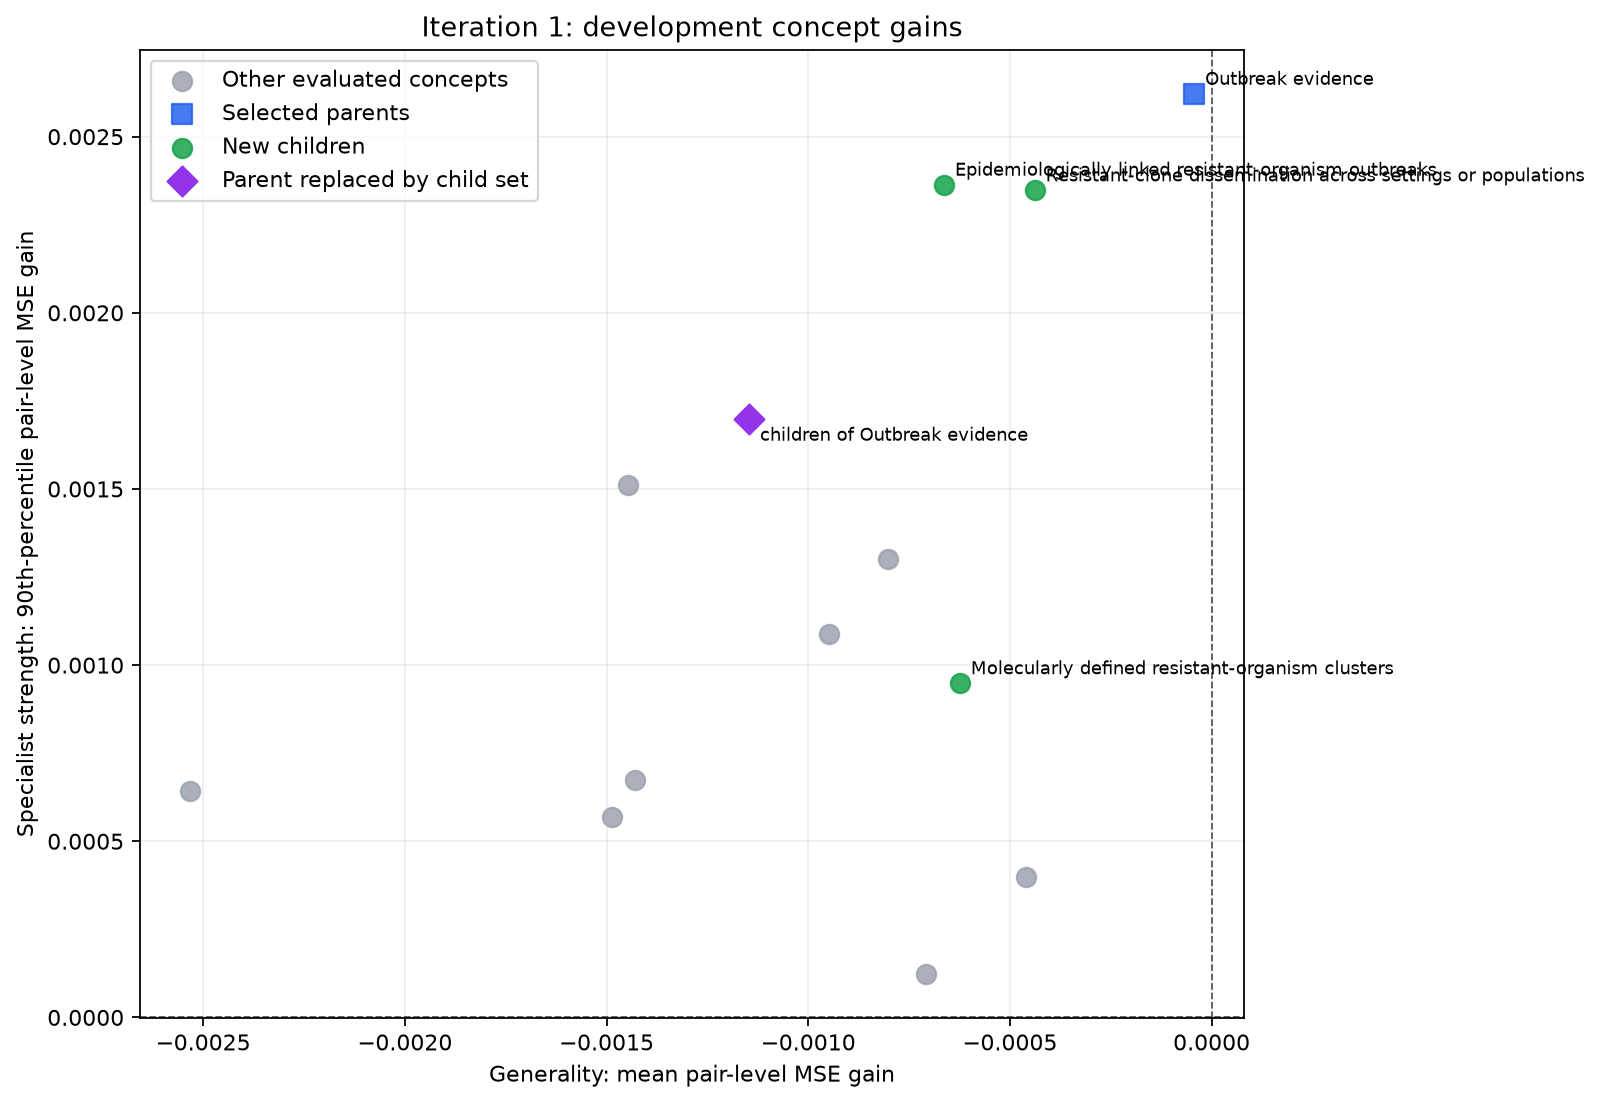

[13:05:55] Iteration 1: progress plot saved to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf/iteration_01_progress.png.
[13:05:55] Iteration 1 result: outbreak_evidence (expanded) → outbreak_evidence_molecularly_defined_resistant_organism_clusters, outbreak_evidence_epidemiologically_linked_resistant_organism_outbreaks, outbreak_evidence_resistant_clone_dissemination_across_settings_or_populations
[13:05:55] Iteration 1/1: round status = evaluated; history saved.
[13:05:55] Iteration 1: OpenAI child-generation usage so far — 1 requests; 11,990 input tokens (11,987 cached); 2,079 output tokens. Remaining account credit is not exposed by the OpenAI model API; check the billing dashboard.
[13:05:55] Final attribution: ranking development pairs by their latest observed SI up to 2023; reporting up to 3 pairs.
Pairs selected by latest observed development SI:
 si_r

In [2]:
automated_refinement_module = importlib.reload(automated_refinement_module)
RESULT = automated_refinement_module.run_automated_concept_refinement(
    PROJECT_ROOT, PARAMETERS, plot_callback=lambda path: display(Image(filename=str(path)))
)


{'run_directory': '/Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf', 'catalog_version': 'bbc4ab803046f670', 'iterations': 1}


,model,reference_model,horizon,generality,specialist_strength,pairs,concept_id,on_pareto_front,eligible_for_expansion
0,concept:outbreak_evidence,baseline,0,-0.000044,0.002622,27,outbreak_evidence,True,False
1,concept:outbreak_evidence_resistant_clone_diss...,baseline,0,-0.000439,0.002348,27,outbreak_evidence_resistant_clone_disseminatio...,False,True
2,concept:hospital_transmission,baseline,0,-0.000459,0.000399,27,hospital_transmission,False,True
3,concept:outbreak_evidence_molecularly_defined_...,baseline,0,-0.000624,0.000949,27,outbreak_evidence_molecularly_defined_resistan...,False,True
4,concept:outbreak_evidence_epidemiologically_li...,baseline,0,-0.000664,0.002364,27,outbreak_evidence_epidemiologically_linked_res...,False,True
5,concept:agricultural_use,baseline,0,-0.000708,0.000123,27,agricultural_use,False,True
6,concept:diagnostics,baseline,0,-0.000801,0.001302,27,diagnostics,False,True
7,concept:policy_guideline_change,baseline,0,-0.000949,0.001089,27,policy_guideline_change,False,True
8,concept:treatment_failure,baseline,0,-0.001431,0.000675,27,treatment_failure,False,True
9,concept:genomic_evidence,baseline,0,-0.001448,0.001512,27,genomic_evidence,False,True


Saved final concept phylogeny: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf/final_concept_phylogeny.png


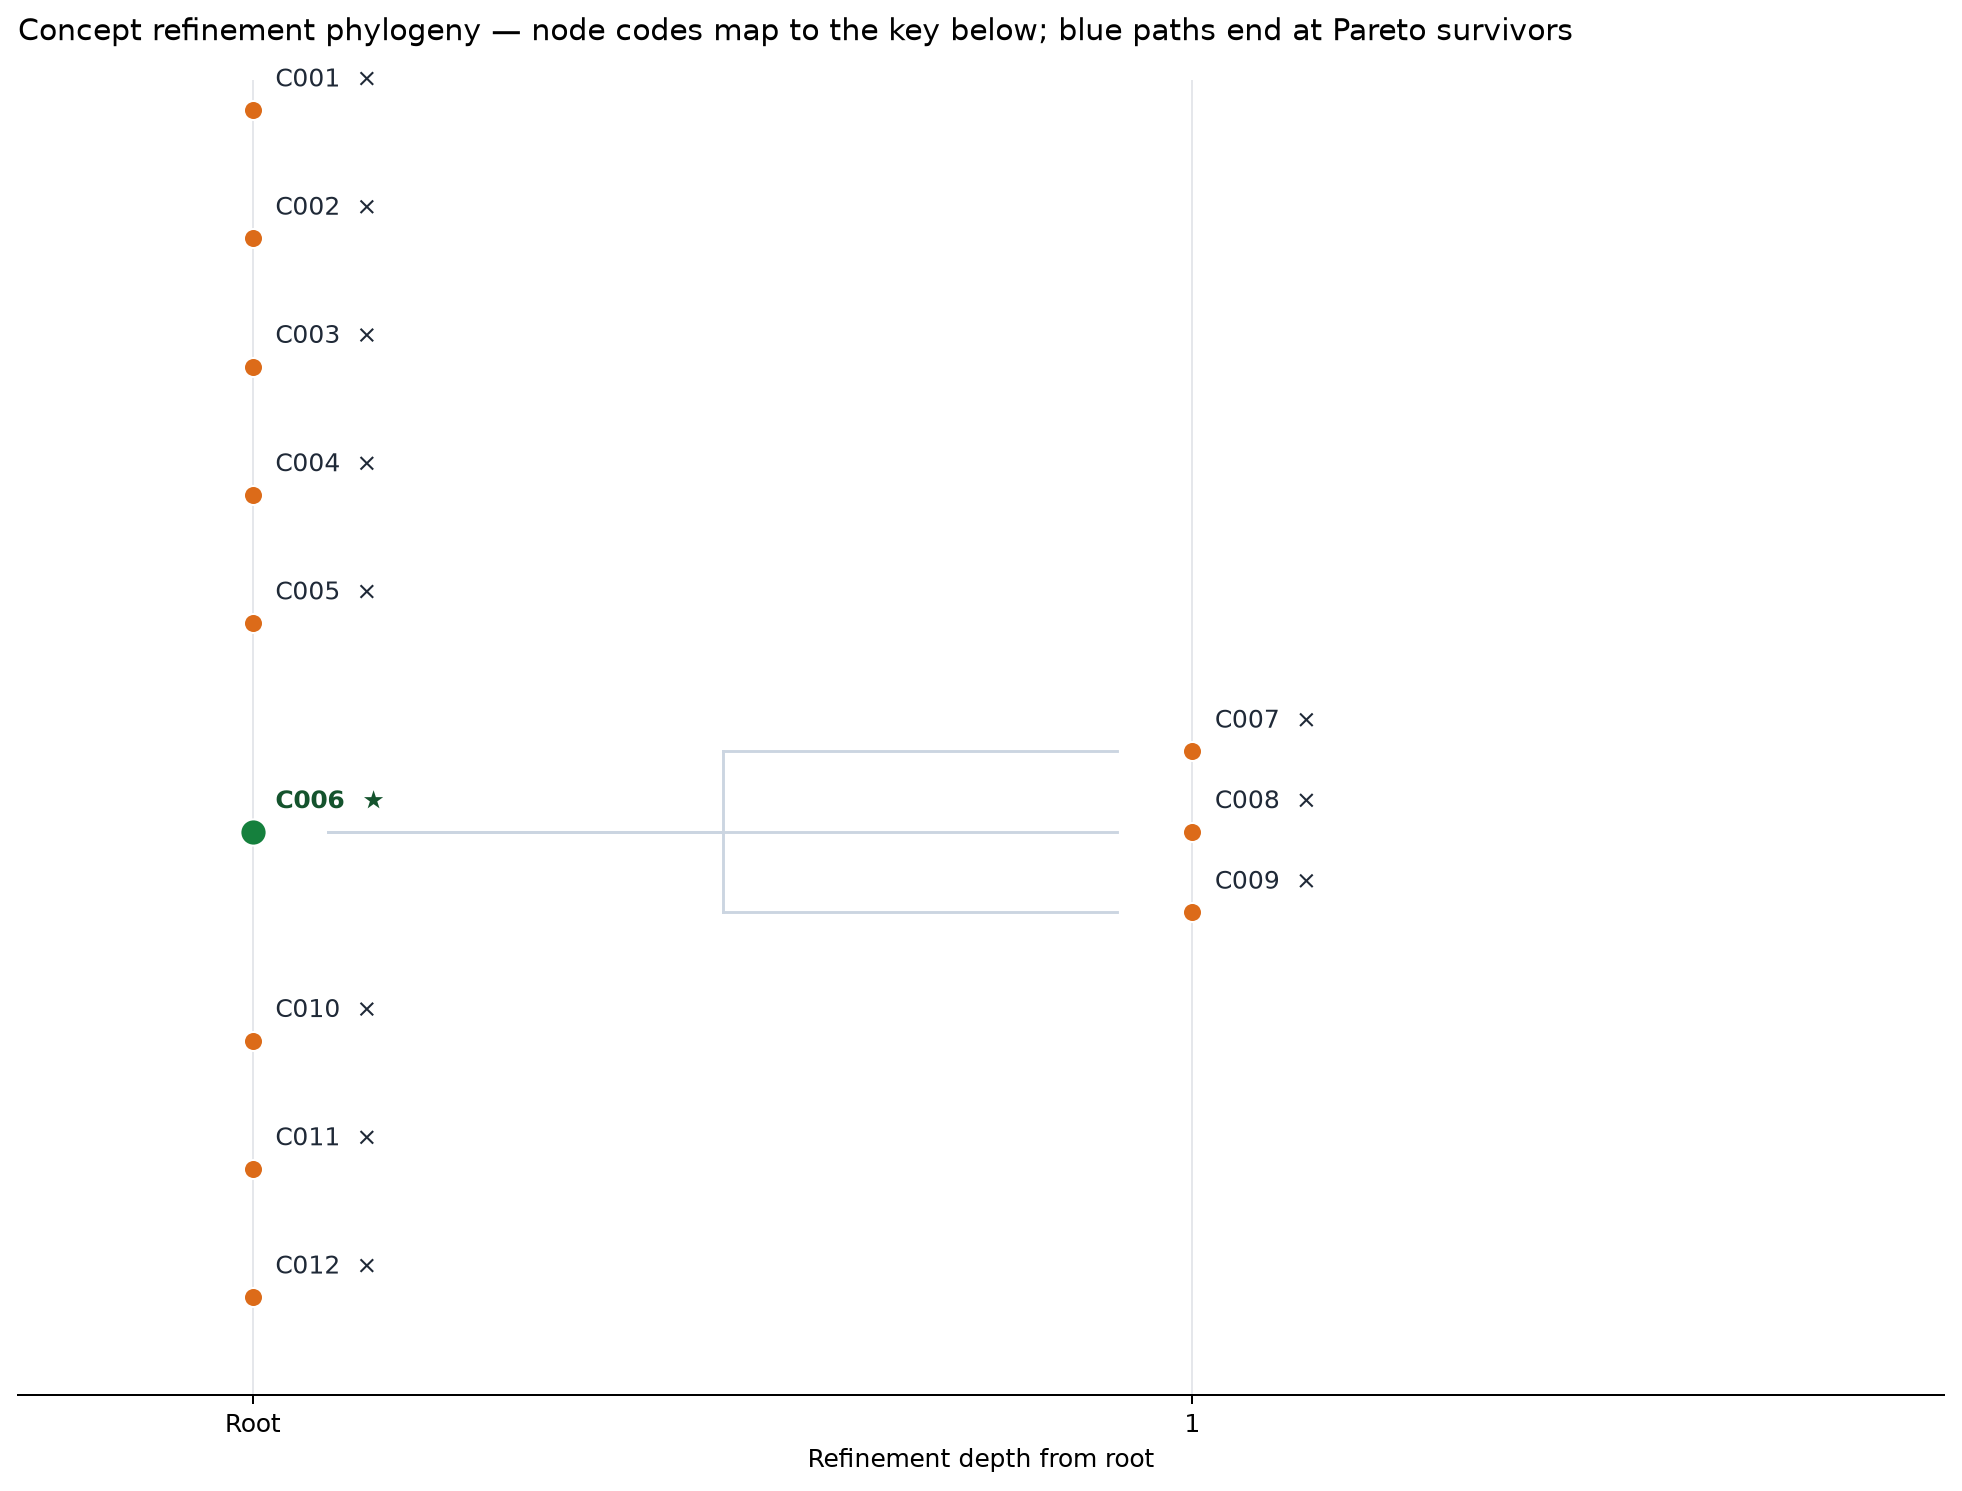

Phylogeny key: code → full concept name, ID, definition, and parent.


,node_label,name,concept_id,definition,parent_label,tree_marker
0,C001,Agricultural use,agricultural_use,"Antimicrobial use or resistance in livestock, ...",NaN,× dead end
1,C002,Diagnostics,diagnostics,Development or evaluation of methods that dete...,NaN,× dead end
2,C003,Genomic evidence,genomic_evidence,Use of genome sequencing or genomic analysis t...,NaN,× dead end
3,C004,Hospital transmission,hospital_transmission,Evidence about transmission or spread of resis...,NaN,× dead end
4,C005,Mechanism discovery,mechanism_discovery,Evidence identifying or characterising a biolo...,NaN,× dead end
5,C006,Outbreak evidence,outbreak_evidence,"Evidence describing a cluster, outbreak, or sp...",NaN,★ survivor
6,C007,Epidemiologically linked resistant-organism ou...,outbreak_evidence_epidemiologically_linked_res...,Evidence of an explicitly described outbreak i...,C006,× dead end
7,C008,Molecularly defined resistant-organism clusters,outbreak_evidence_molecularly_defined_resistan...,Evidence of clusters involving antimicrobial-r...,C006,× dead end
8,C009,Resistant-clone dissemination across settings ...,outbreak_evidence_resistant_clone_disseminatio...,"Evidence explicitly describing dissemination, ...",C006,× dead end
9,C010,Policy or guideline change,policy_guideline_change,"Changes to formal policy, clinical guidelines,...",NaN,× dead end


Development pairs selected by SI:


,si_rank,pathogen,antibiotic,si_rank_year,si_at_rank
0,1,Mycobacterium tuberculosis,Rifampicin,2023,0.936739
1,2,Salmonella enterica,Ciprofloxacin,2023,0.467154
2,3,Salmonella enterica,Chloramphenicol,2023,0.444590


Per-pair exploratory concept ranking (0 = equal-weight horizons 1–3):


,pathogen,antibiotic,split,concept_id,concept_name,horizon,historical_contribution,historical_contribution_ci_lower,historical_contribution_ci_upper,effect_per_10_percentage_points,...,effect_per_10pp_ci_upper,n_pair_origins,n_positive_exposure_origins,status,causal_interpretation,causal_rank,effect_direction,si_rank,si_rank_year,si_at_rank
0,Mycobacterium tuberculosis,Rifampicin,development,surveillance,Surveillance,0,-0.148437,NaN,NaN,-0.039185,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,lower SI,1,2023,0.936739
5,Mycobacterium tuberculosis,Rifampicin,development,diagnostics,Diagnostics,0,-0.112902,NaN,NaN,-0.020896,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,2,lower SI,1,2023,0.936739
3,Mycobacterium tuberculosis,Rifampicin,development,mechanism_discovery,Mechanism discovery,0,-0.104910,NaN,NaN,-0.031429,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,3,lower SI,1,2023,0.936739
1,Mycobacterium tuberculosis,Rifampicin,development,outbreak_evidence,Outbreak evidence,0,-0.069845,NaN,NaN,-0.084811,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,4,lower SI,1,2023,0.936739
2,Mycobacterium tuberculosis,Rifampicin,development,treatment_failure,Treatment failure,0,0.062233,NaN,NaN,0.070371,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,5,higher SI,1,2023,0.936739
4,Mycobacterium tuberculosis,Rifampicin,development,genomic_evidence,Genomic evidence,0,0.050547,NaN,NaN,0.023733,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,6,higher SI,1,2023,0.936739
10,Mycobacterium tuberculosis,Rifampicin,development,outbreak_evidence_epidemiologically_linked_res...,Epidemiologically linked resistant-organism ou...,0,-0.037108,NaN,NaN,-0.110530,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,7,lower SI,1,2023,0.936739
6,Mycobacterium tuberculosis,Rifampicin,development,hospital_transmission,Hospital transmission,0,0.033932,NaN,NaN,0.123840,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,8,higher SI,1,2023,0.936739
9,Mycobacterium tuberculosis,Rifampicin,development,outbreak_evidence_molecularly_defined_resistan...,Molecularly defined resistant-organism clusters,0,0.025394,NaN,NaN,0.034406,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,9,higher SI,1,2023,0.936739
11,Mycobacterium tuberculosis,Rifampicin,development,outbreak_evidence_resistant_clone_disseminatio...,Resistant-clone dissemination across settings ...,0,0.022470,NaN,NaN,0.062999,...,NaN,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,10,higher SI,1,2023,0.936739


,pathogen,antibiotic,split,concept_id,concept_name,horizon,historical_contribution,historical_contribution_ci_lower,historical_contribution_ci_upper,effect_per_10_percentage_points,effect_per_10pp_ci_lower,effect_per_10pp_ci_upper,n_pair_origins,n_positive_exposure_origins,status,causal_interpretation,si_rank,si_rank_year,si_at_rank
0,Mycobacterium tuberculosis,Rifampicin,development,surveillance,Surveillance,1,-0.163162,-0.367113,0.040789,-0.043013,-0.096826,0.010801,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,2023,0.936739
1,Mycobacterium tuberculosis,Rifampicin,development,outbreak_evidence,Outbreak evidence,1,-0.078241,-0.185484,0.029003,-0.095064,-0.225958,0.035829,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,2023,0.936739
2,Mycobacterium tuberculosis,Rifampicin,development,treatment_failure,Treatment failure,1,0.037059,-0.026121,0.100239,0.041677,-0.029812,0.113165,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,2023,0.936739
3,Mycobacterium tuberculosis,Rifampicin,development,mechanism_discovery,Mechanism discovery,1,-0.208542,-0.406826,-0.010259,-0.062277,-0.121893,-0.002662,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,2023,0.936739
4,Mycobacterium tuberculosis,Rifampicin,development,genomic_evidence,Genomic evidence,1,0.049274,-0.076678,0.175225,0.021114,-0.035905,0.078132,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,1,2023,0.936739
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,Salmonella enterica,Ciprofloxacin,development,agricultural_use,Agricultural use,3,-0.013544,-0.155822,0.128735,-0.006490,-0.062222,0.049242,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,2,2023,0.467154
104,Salmonella enterica,Ciprofloxacin,development,policy_guideline_change,Policy or guideline change,3,-0.006237,-0.088031,0.075558,-0.012922,-0.198930,0.173086,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,2,2023,0.467154
105,Salmonella enterica,Ciprofloxacin,development,outbreak_evidence_molecularly_defined_resistan...,Molecularly defined resistant-organism clusters,3,0.034124,-0.109164,0.177413,0.019858,-0.062431,0.102148,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,2,2023,0.467154
106,Salmonella enterica,Ciprofloxacin,development,outbreak_evidence_epidemiologically_linked_res...,Epidemiologically linked resistant-organism ou...,3,-0.146102,-0.251229,-0.040975,-0.204598,-0.353789,-0.055406,14,14,assumption_dependent,Exploratory counterfactual attribution; causal...,2,2023,0.467154


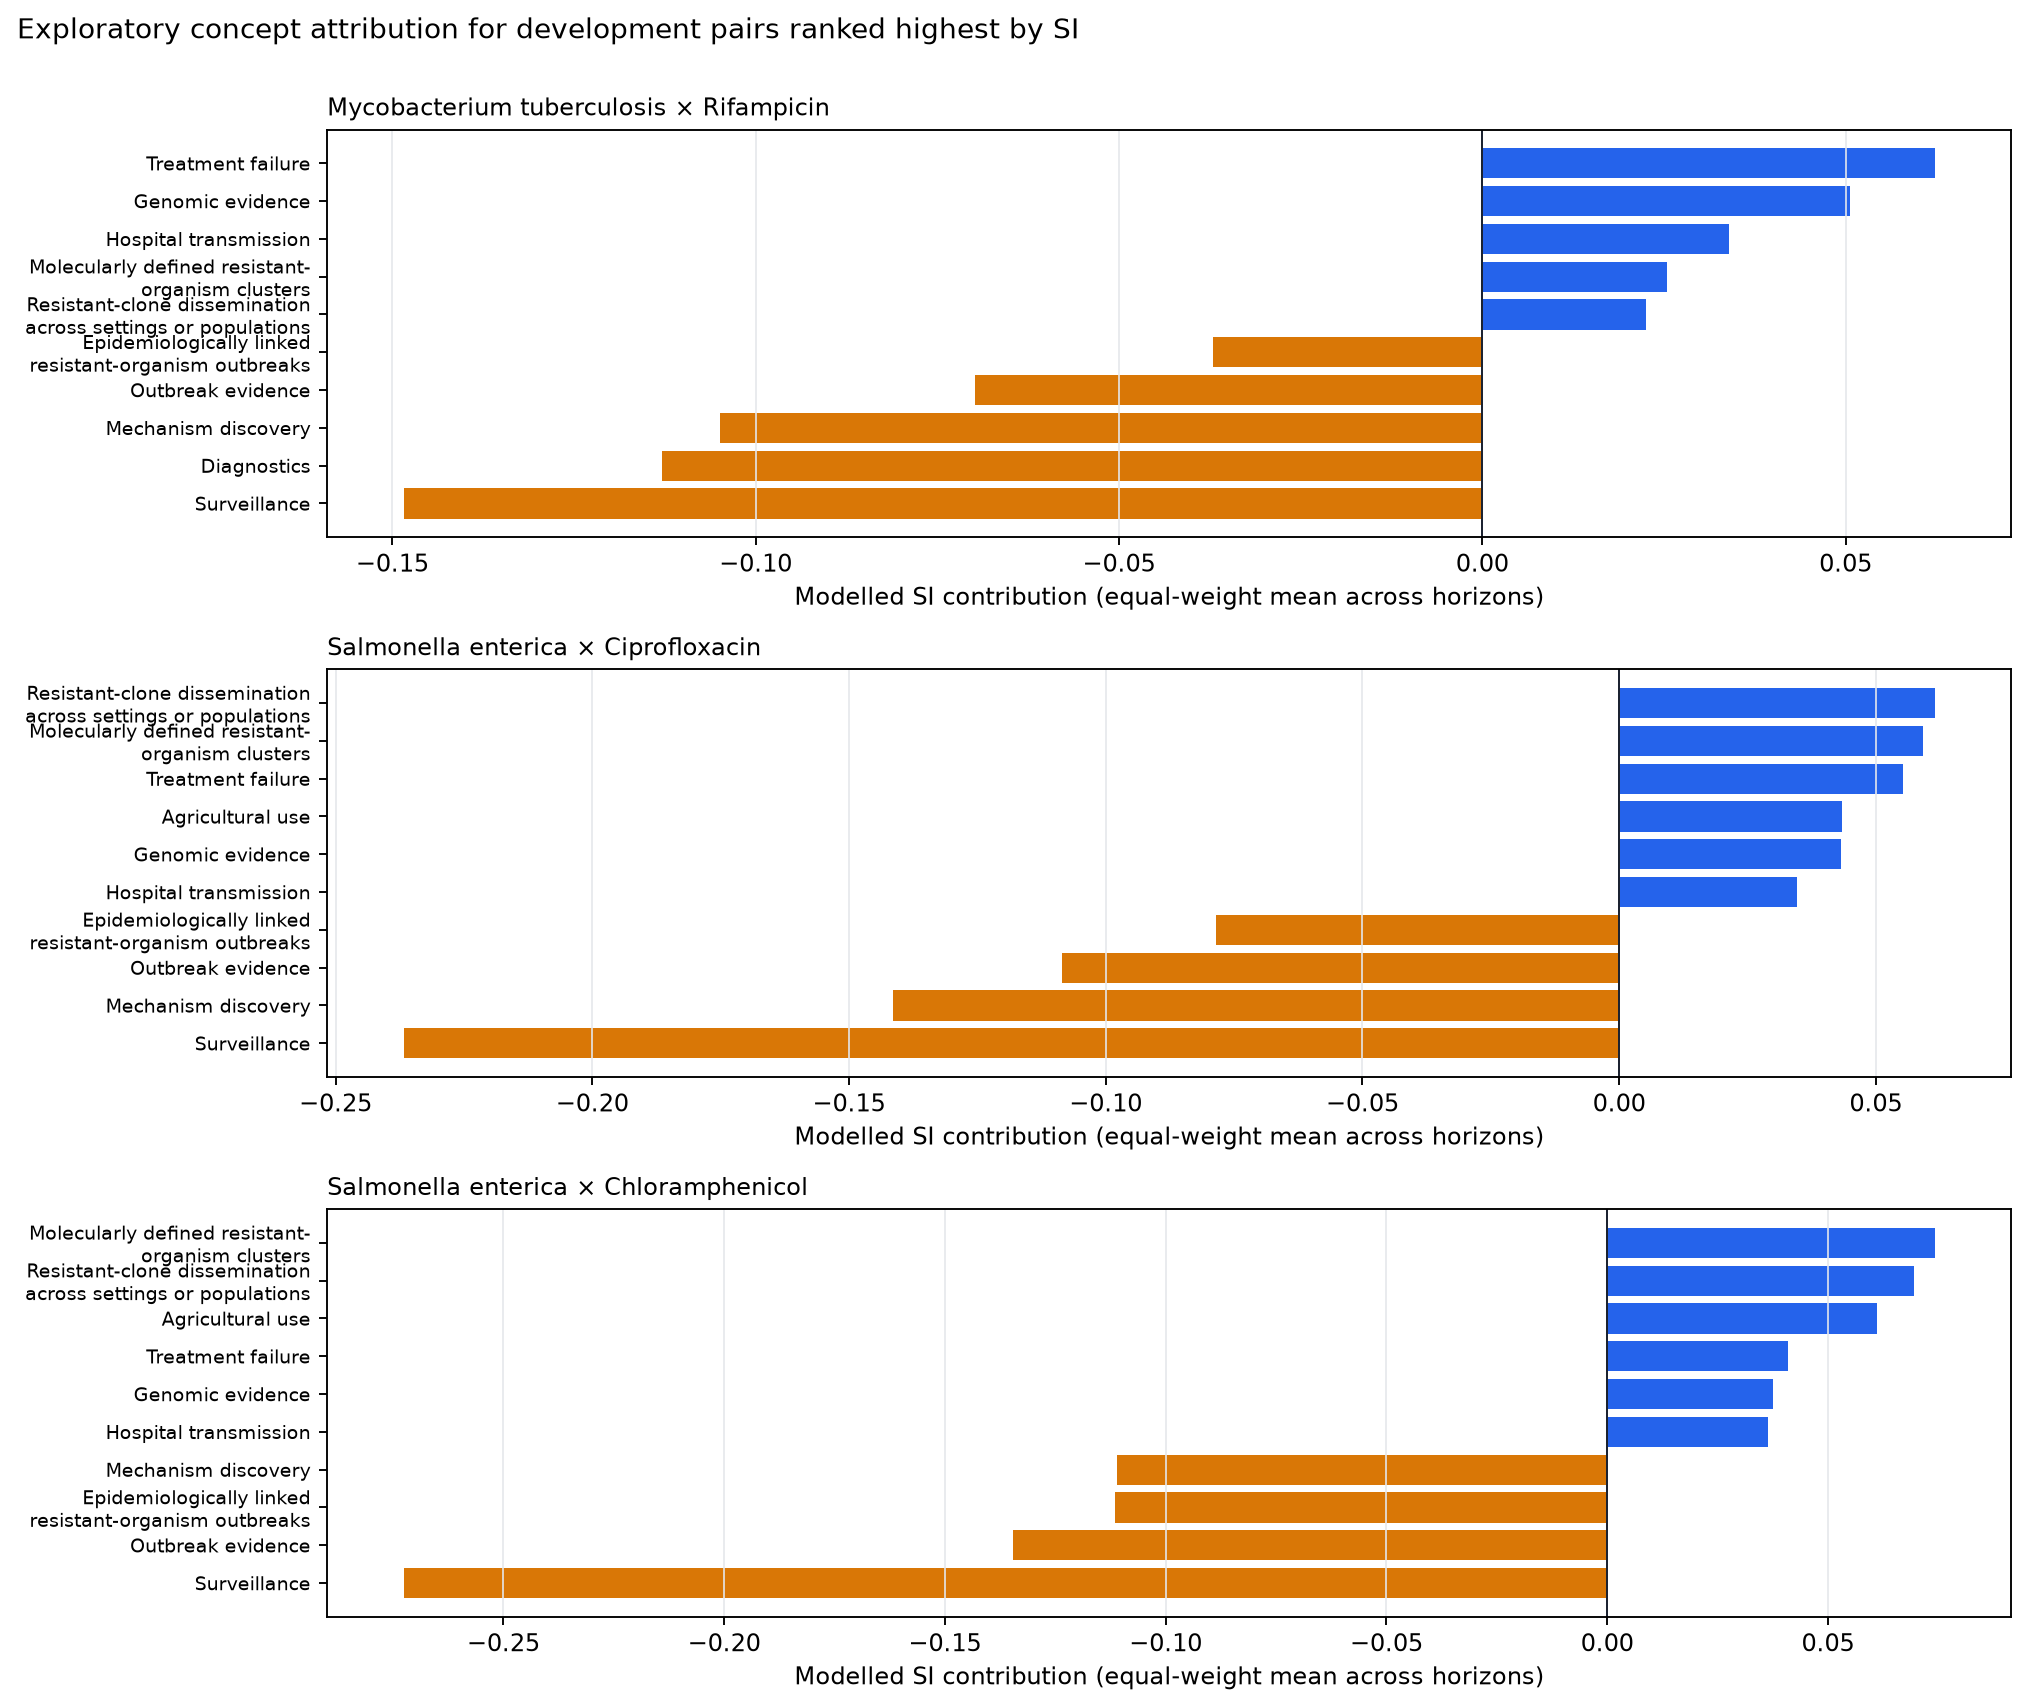

Saved pair selection: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf/attribution_selected_pairs_by_si.csv
Saved rankings: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf/exploratory_pair_attribution_rankings.parquet
Saved horizon estimates: /Users/f.costa/Code/Antimicrobial-Resistance/outputs/concept_search/automated_refinement/corpus_1de2a45803e0_catalog_54d79903b1dbf073_n1_k3_c3_fit2000-2023_l3_h1-2-3_994630bf/exploratory_pair_attribution_horizons.parquet


In [3]:
RESULT = automated_refinement_module.restore_automated_result_artifacts(RESULT)
if RESULT.get("status") == "disabled":
    print(RESULT["status"])
else:
    print({"run_directory": str(RESULT["run_directory"]), "catalog_version": RESULT["catalog_version"], "iterations": len(RESULT["round_log"])})
    display(RESULT["final_frontier"].head(FRONTIER_DISPLAY_ROWS))
    print("Saved final concept phylogeny:", RESULT["phylogeny_path"])
    if RESULT["phylogeny_path"] is not None:
        display(Image(filename=str(RESULT["phylogeny_path"])))
        print("Phylogeny key: code → full concept name, ID, definition, and parent.")
        display(RESULT["phylogeny_node_key"][["node_label", "name", "concept_id", "definition", "parent_label", "tree_marker"]])
    print("Development pairs selected by SI:")
    display(RESULT["attribution_selected_pairs"][["si_rank", "pathogen", "antibiotic", "si_rank_year", "si_at_rank"]])
    print("Per-pair exploratory concept ranking (0 = equal-weight horizons 1–3):")
    display(RESULT["attribution_ranking"].sort_values(["si_rank", "causal_rank", "concept_id"], na_position="last"))
    display(RESULT["attribution_horizons"])
    if RESULT["attribution_plot_path"] is not None:
        display(Image(filename=str(RESULT["attribution_plot_path"])))
    print("Saved pair selection:", RESULT["attribution_selected_pairs_path"])
    print("Saved rankings:", RESULT["attribution_ranking_path"])
    print("Saved horizon estimates:", RESULT["attribution_horizons_path"])


## Final exploratory attribution for high-SI development pairs

`ATTRIBUTION_NUM_PAIRS` controls how many pairs are included (default 3). Pairs are selected from the development partition only, ranked by their latest observed SI at or before `FORECAST_ORIGIN_END_YEAR`; the selected SI value and year are printed and saved. The frozen working catalog is then used to compute horizon-specific and equal-weight per-pair concept attributions, with shared coefficients fit on development pairs. The plot shows up to ten supported concepts per selected pair; the saved tables retain every concept and its support/status.

These estimates are exploratory and assumption-dependent, not identified causal effects. They need a well-defined intervention on abstract prevalence, adequate overlap, and no unmeasured time-varying confounding. The data do not include all potential drivers such as AMR burden, policy, or surveillance change. Read the `status`, origin counts, and interval columns alongside the ranks. This attribution is reported separately from the forecast Pareto selection and does not use confirmation-pair outcomes.

Inspect `iteration_history.json`, per-round proposals and forecasts, the final Pareto table, and the attribution tables. Confirm the children’s definitions and hierarchy, then use notebook 10e to evaluate the frozen catalog on confirmation pairs. Update its expected catalog hash to the final catalog version before running it. Do not use confirmation results to revise the vocabulary.